## преобразование хаара (3 ступени)

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

(512, 512)


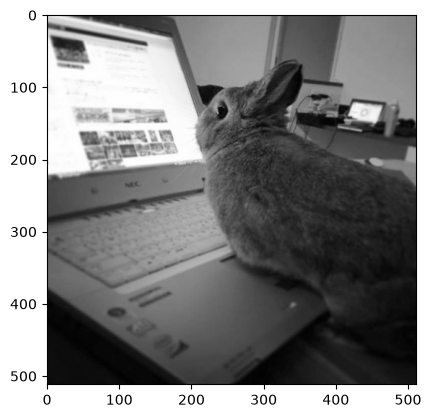

In [2]:
image_gray = cv2.imread('img.jpg', cv2.IMREAD_GRAYSCALE)
print(image_gray.shape)
plt.imshow(image_gray, cmap='gray')

In [3]:
# 
# LL (приближение), LH (вертикальные границы), HL (горизонтальные границы), HH (диагонали)

def haar_level(img):
    img = img.astype(np.float64)

    L = (img[:, 0::2] + img[:, 1::2]) / 2
    H = (img[:, 0::2] - img[:, 1::2]) / 2

    LL = (L[0::2, :] + L[1::2, :]) / 2
    HL = (L[0::2, :] - L[1::2, :]) / 2
    LH = (H[0::2, :] + H[1::2, :]) / 2
    HH = (H[0::2, :] - H[1::2, :]) / 2

    return LL, LH, HL, HH

In [4]:
levels = 3
coeffs = []
approx = [image_gray.astype(np.float64)]
current = image_gray

for level in range(levels):
    LL, LH, HL, HH = haar_level(current)
    coeffs.append((LH, HL, HH))
    approx.append(LL)
    current = LL
    print(f'level {level + 1}: LL {LL.shape}, LH {LH.shape}, HL {HL.shape}, HH {HH.shape}')

level 1: LL (256, 256), LH (256, 256), HL (256, 256), HH (256, 256)
level 2: LL (128, 128), LH (128, 128), HL (128, 128), HH (128, 128)
level 3: LL (64, 64), LH (64, 64), HL (64, 64), HH (64, 64)


In [5]:
def show_4_imgs(A11, A12, A21, A22, title):
    fig, ax = plt.subplots(1, 4, figsize=(15, 5))
    ax[0].imshow(np.abs(A11), cmap='gray'); ax[0].set_title('Среднее')
    ax[1].imshow(np.abs(A12), cmap='gray'); ax[1].set_title('Вертикальные перепады')
    ax[2].imshow(np.abs(A21), cmap='gray'); ax[2].set_title('Горизонтальные перепады')
    ax[3].imshow(np.abs(A22), cmap='gray'); ax[3].set_title('Диагональные перепады')
    fig.suptitle(title)
    plt.show()

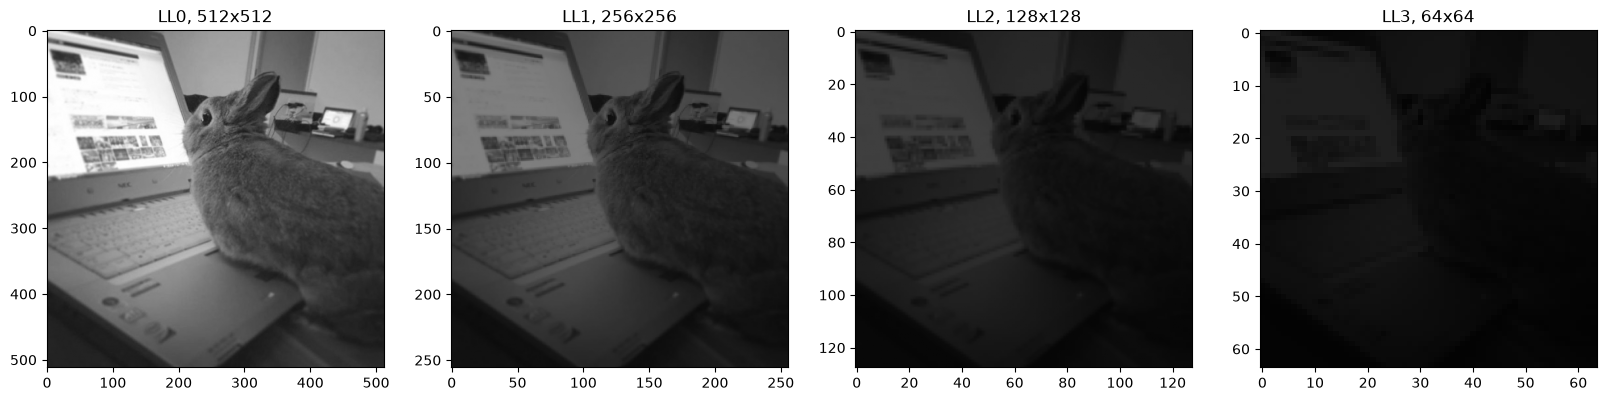

In [6]:
fig, axs = plt.subplots(1, levels + 1, figsize=(20, 5))

for k, ax in enumerate(axs):
    ax.imshow(approx[k] / 2**k, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'LL{k}, {approx[k].shape[0]}x{approx[k].shape[1]}')
plt.show()

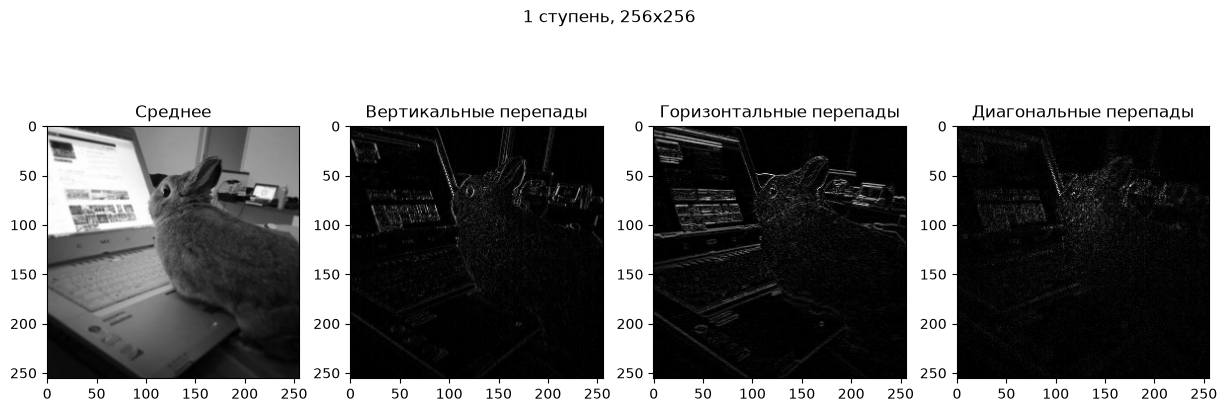

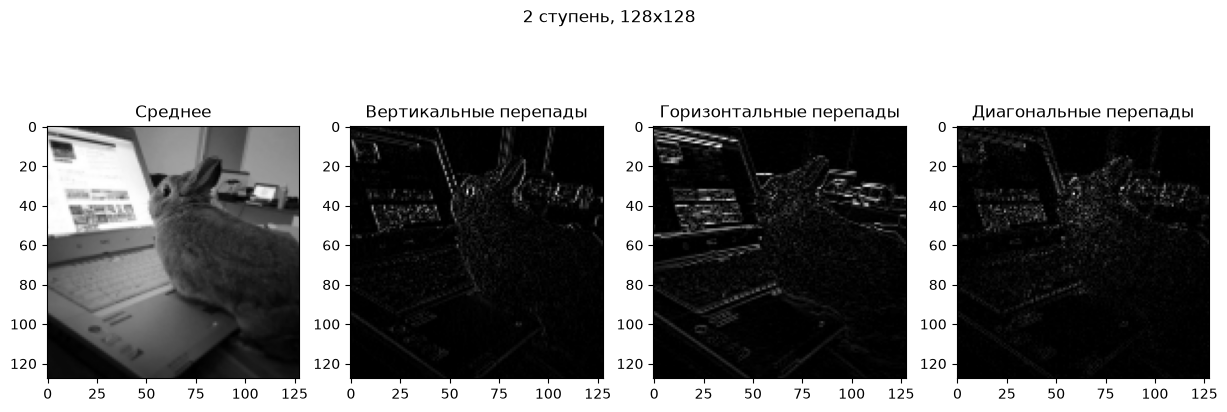

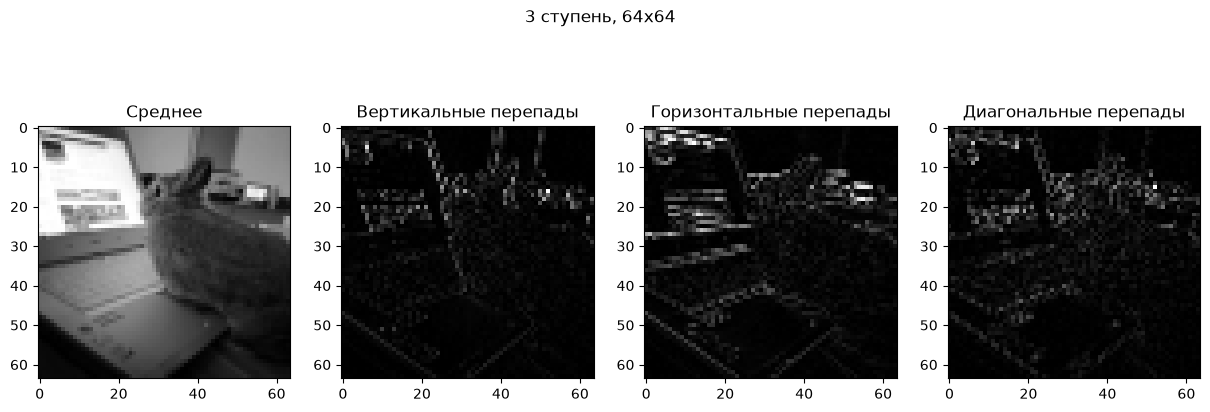

In [7]:
for level in range(levels):
    LH, HL, HH = coeffs[level]
    LL = approx[level + 1]
    show_4_imgs(LL, LH, HL, HH, f'{level + 1} ступень, {LL.shape[0]}x{LL.shape[1]}')